# 06_compare — does the text help? (the headline result)

Compares the three models from `05_train` on the **same test projects** (approved FY2012+):
structured-only vs text-only vs combined.

The key question isn't just "is combined AUC higher?" but "**is the difference bigger than chance?**" — answered with a **paired bootstrap**.

**Attach to:** `wb-ml-single`.

## Settings

**What:** imports, experiment path, bootstrap size.

**Why:** 2,000 resamples gives stable 95% intervals in a few seconds.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score

CATALOG = "dbw_wb_outcome"
N_BOOT = 2000
SEED = 42
ME = spark.sql("select current_user()").first()[0]
EXPERIMENT = f"/Users/{ME}/wb-outcome/wb_outcome_experiment"
from databricks.sdk import WorkspaceClient
WorkspaceClient().workspace.mkdirs(f"/Users/{ME}/wb-outcome")   # the experiment's parent folder must exist
mlflow.set_experiment(EXPERIMENT)

<Experiment: artifact_location='dbfs:/databricks/mlflow-tracking/1689269027677107', creation_time=1792042453420, experiment_id='1689269027677107', last_update_time=1792169060015, lifecycle_stage='active', name='/Users/<user>/wb-outcome/wb_outcome_experiment', tags={'mlflow.experiment.sourceName': '/Users/<user>/wb-outcome/wb_outcome_experiment',
 'mlflow.experimentType': 'MLFLOW_EXPERIMENT',
 'mlflow.ownerEmail': '<user>',
 'mlflow.ownerId': '142949886705954'}>

## 1. Metrics table from MLflow

**What:** finds the latest parent run per feature set (tag `stage = ablation`, not a nested trial) and lines up their test metrics.

**Why:** reading from MLflow (not re-computing) guarantees the table matches exactly what was logged with each model.

In [2]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT],
                          filter_string="tags.stage = 'ablation'", order_by=["start_time DESC"])
runs = runs[runs["tags.mlflow.parentRunId"].isna()] if "tags.mlflow.parentRunId" in runs else runs
latest = runs.drop_duplicates("tags.feature_set").set_index("tags.feature_set")
cols = {"metrics.test_auc": "test_auc", "metrics.test_auc_ci_low": "auc_ci_low", "metrics.test_auc_ci_high": "auc_ci_high",
        "metrics.test_pr_auc_failure": "pr_auc_failure", "metrics.test_failure_rate": "pr_auc_random_baseline",
        "metrics.test_f1_failure": "f1_failure", "metrics.test_precision_failure": "precision_failure",
        "metrics.test_recall_failure": "recall_failure", "metrics.test_brier": "brier", "metrics.val_auc": "val_auc"}
table = latest[list(cols)].rename(columns=cols).loc[["structured", "text", "combined"]].round(4)
table["run_id"] = latest.loc[table.index, "run_id"]
display(table.reset_index().rename(columns={"tags.feature_set": "feature_set"}))

feature_set,test_auc,auc_ci_low,auc_ci_high,pr_auc_failure,pr_auc_random_baseline,f1_failure,precision_failure,recall_failure,brier,val_auc,run_id
structured,0.6017,0.5734,0.6301,0.2691,0.2003,0.3518,0.2318,0.7297,0.1604,0.6131,6c1b2852aedf44f0bca65f1730e26b82
text,0.5758,0.5471,0.6073,0.267,0.2003,0.3397,0.2112,0.8671,0.1624,0.5787,39d3072daf2f43a2b45f2d10016f8582
combined,0.5888,0.5595,0.6194,0.2616,0.2003,0.337,0.226,0.6622,0.1627,0.6066,1cd3b7683b9141508af567c4a999cf37


## 2. Paired bootstrap: is the gain real?

**What:** resamples the test projects with replacement 2,000 times; each time computes AUC(combined) − AUC(structured) (and − AUC(text)) **on the same resampled projects**. Reports the mean gain, its 95% interval, and how often the gain was ≤ 0.

**Why:** comparing two separate confidence intervals is too conservative because both models are scored on the same projects — their errors are correlated. Pairing removes that shared noise. If the 95% interval excludes 0, the text features add real signal on unseen future projects.

In [3]:
preds = spark.table(f"{CATALOG}.gold.test_predictions").toPandas()
wide = preds.pivot_table(index=["project_id", "label"], columns="feature_set", values="prob_success").reset_index()
y = wide["label"].values
rng = np.random.default_rng(SEED)

def paired(a, b):
    diffs = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))
        if 0 < y[idx].sum() < len(idx):
            diffs.append(roc_auc_score(y[idx], wide[a].values[idx]) - roc_auc_score(y[idx], wide[b].values[idx]))
    diffs = np.array(diffs)
    return {"comparison": f"{a} - {b}",
            "auc_gain": round(roc_auc_score(y, wide[a]) - roc_auc_score(y, wide[b]), 4),
            "ci_low": round(float(np.percentile(diffs, 2.5)), 4),
            "ci_high": round(float(np.percentile(diffs, 97.5)), 4),
            "share_gain_le_0": round(float((diffs <= 0).mean()), 4)}

gains = pd.DataFrame([paired("combined", "structured"), paired("combined", "text"), paired("text", "structured")])
display(gains)

comparison,auc_gain,ci_low,ci_high,share_gain_le_0
combined - structured,-0.0129,-0.032,0.0069,0.902
combined - text,0.0129,-0.0088,0.0356,0.1225
text - structured,-0.0258,-0.0573,0.0045,0.95


## 3. ROC and precision-recall curves

**What:** ROC curves (success class) and precision-recall curves (failure class) for the three models on one chart each.

**Why:** a single number hides *where* a model is better. The PR chart shows, for example, whether the combined model finds the riskiest projects with fewer false alarms at the top of its list — the part a reviewer would actually use.

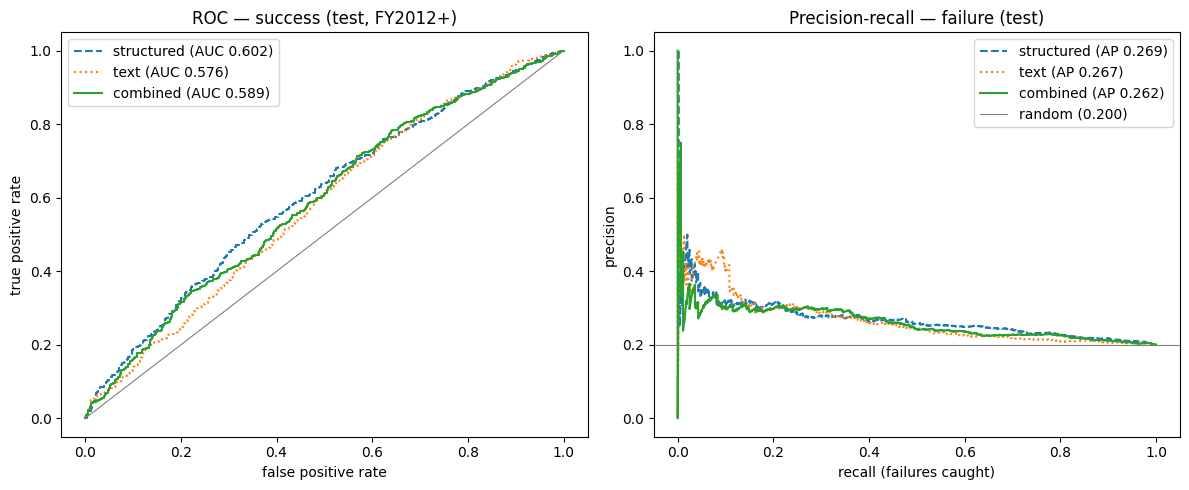

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for fs, style in [("structured", "--"), ("text", ":"), ("combined", "-")]:
    p = wide[fs].values
    fpr, tpr, _ = roc_curve(y, p)
    axes[0].plot(fpr, tpr, style, label=f"{fs} (AUC {roc_auc_score(y, p):.3f})")
    prec, rec, _ = precision_recall_curve(1 - y, 1 - p)
    axes[1].plot(rec, prec, style, label=f"{fs} (AP {average_precision_score(1 - y, 1 - p):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", lw=0.8)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC — success (test, FY2012+)")
axes[1].axhline((1 - y).mean(), color="gray", lw=0.8, label=f"random ({(1 - y).mean():.3f})")
axes[1].set(xlabel="recall (failures caught)", ylabel="precision", title="Precision-recall — failure (test)")
for ax in axes:
    ax.legend()
fig.tight_layout()
display(fig)

## 4. Log the comparison and save it

**What:** logs the tables and chart to an MLflow run named `ablation_comparison` and saves both tables to `gold.model_comparison` / `gold.model_comparison_gains`.

**Why:** the headline result lives next to the models it describes (MLflow) and is queryable by SQL / dashboards (gold tables).

In [5]:
with mlflow.start_run(run_name="ablation_comparison"):
    mlflow.set_tag("stage", "comparison")
    mlflow.log_figure(fig, "roc_pr_curves.png")
    mlflow.log_table(table.reset_index().rename(columns={"tags.feature_set": "feature_set"}), "metrics_table.json")
    mlflow.log_table(gains, "paired_bootstrap.json")
    cg = gains.iloc[0]
    mlflow.log_metrics({"auc_gain_combined_vs_structured": cg.auc_gain,
                        "auc_gain_ci_low": cg.ci_low, "auc_gain_ci_high": cg.ci_high})
plt.close(fig)

spark.createDataFrame(table.reset_index().rename(columns={"tags.feature_set": "feature_set"})) \
    .write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(f"{CATALOG}.gold.model_comparison")
spark.createDataFrame(gains).write.mode("overwrite").option("overwriteSchema", "true") \
    .saveAsTable(f"{CATALOG}.gold.model_comparison_gains")

s, c = table.loc["structured"], table.loc["combined"]
headline = (f"Adding pre-approval document text changed test AUC from {s.test_auc:.3f} (structured only) "
            f"to {c.test_auc:.3f} (combined): {cg.auc_gain:+.3f}, paired 95% CI [{cg.ci_low:+.3f}, {cg.ci_high:+.3f}]. "
            f"PR-AUC for failures: {s.pr_auc_failure:.3f} -> {c.pr_auc_failure:.3f} (random = {c.pr_auc_random_baseline:.3f}).")
print(headline)
dbutils.notebook.exit(json.dumps({"headline": headline,
                                  "table": table.drop(columns="run_id").reset_index().to_dict("records"),
                                  "gains": gains.to_dict("records")}))

{"headline": "Adding pre-approval document text changed test AUC from 0.602 (structured only) to 0.589 (combined): -0.013, paired 95% CI [-0.032, +0.007]. PR-AUC for failures: 0.269 -> 0.262 (random = 0.200).", "table": [{"tags.feature_set": "structured", "test_auc": 0.6017, "auc_ci_low": 0.5734, "auc_ci_high": 0.6301, "pr_auc_failure": 0.2691, "pr_auc_random_baseline": 0.2003, "f1_failure": 0.3518, "precision_failure": 0.2318, "recall_failure": 0.7297, "brier": 0.1604, "val_auc": 0.6131}, {"tags.feature_set": "text", "test_auc": 0.5758, "auc_ci_low": 0.5471, "auc_ci_high": 0.6073, "pr_auc_failure": 0.267, "pr_auc_random_baseline": 0.2003, "f1_failure": 0.3397, "precision_failure": 0.2112, "recall_failure": 0.8671, "brier": 0.1624, "val_auc": 0.5787}, {"tags.feature_set": "combined", "test_auc": 0.5888, "auc_ci_low": 0.5595, "auc_ci_high": 0.6194, "pr_auc_failure": 0.2616, "pr_auc_random_baseline": 0.2003, "f1_failure": 0.337, "precision_failure": 0.226, "recall_failure": 0.6622, "brie